This demonstration is largely based on a [scikit-learn example](https://scikit-learn.org/stable/auto_examples/cluster/plot_cluster_iris.html).

In [1]:
%matplotlib inline

# K-means Clustering

The data: the 150 [Iris](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html) flowers, described by 4 features (sepal and petal length and width), from three species. K-means doesn't see the species: they only serve to judge the result.

We compare three models, in the order of the plots:

1. 3 clusters;
2. 3 clusters, with a bad initialization: `init="random"` (initial centroids drawn at random among the points, instead of k-means++) and `n_init=1` (a single run);
3. 8 clusters;

then the ground truth, the species.

`n_init` is the number of runs from different initial centroids: k-means keeps the one with the lowest inertia. By default (`n_init="auto"`, since scikit-learn 1.4), it is 1 run with k-means++ and 10 with `init="random"`.

In [2]:
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

iris = datasets.load_iris()
X = iris.data  # 150 flowers, 4 features (sepal and petal length and width)
y = iris.target  # the species (0, 1 or 2), which k-means doesn't see

## Three Models

For each model:

- the inertia, what k-means minimizes: the sum of the squared distances of each point to its centroid;
- the adjusted Rand index (ARI), which compares the clusters with the species: 1 = identical partition, ≈ 0 = chance.

In [3]:
models = {
  "3 clusters": KMeans(n_clusters=3, random_state=0),
  "3 clusters, bad initialization": KMeans(
    n_clusters=3, init="random", n_init=1, random_state=5
  ),
  "8 clusters": KMeans(n_clusters=8, random_state=0),
}
for title, model in models.items():
  model.fit(X)
  ari = adjusted_rand_score(y, model.labels_)
  print(f"{title}: inertia {model.inertia_:.1f}, ARI {ari:.2f}")

3 clusters: inertia 78.9, ARI 0.72
3 clusters, bad initialization: inertia 142.8, ARI 0.43
8 clusters: inertia 30.1, ARI 0.46


The four partitions, on three of the four features (the clusters' colors are arbitrary: only the groups matter):

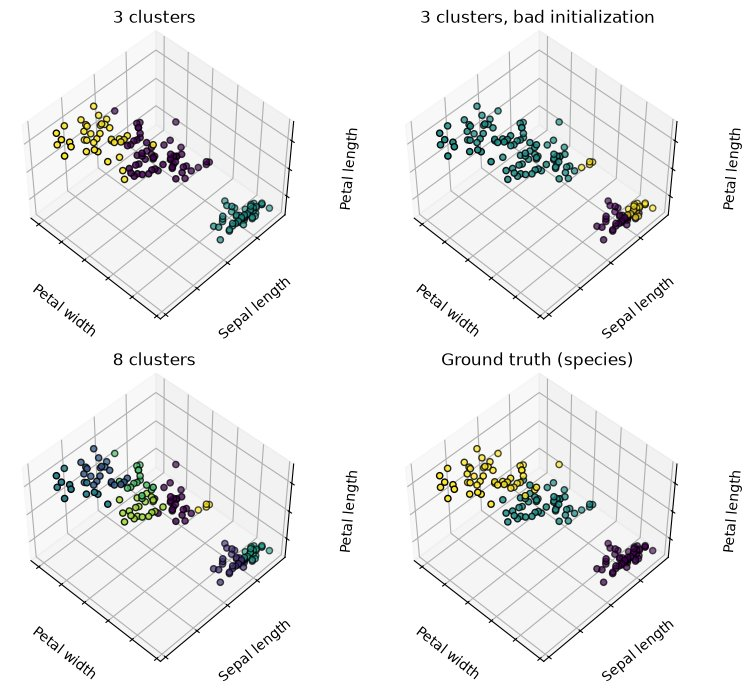

In [4]:
panels = [(title, model.labels_) for title, model in models.items()]
panels.append(("Ground truth (species)", y))

fig = plt.figure(figsize=(8, 7))
for i, (title, labels) in enumerate(panels, start=1):
  ax = fig.add_subplot(2, 2, i, projection="3d", elev=48, azim=134)
  ax.scatter(X[:, 3], X[:, 0], X[:, 2], c=labels, edgecolor="k")
  ax.xaxis.set_ticklabels([])
  ax.yaxis.set_ticklabels([])
  ax.zaxis.set_ticklabels([])
  ax.set_xlabel("Petal width")
  ax.set_ylabel("Sepal length")
  ax.set_zlabel("Petal length")
  ax.set_title(title)
plt.tight_layout()
plt.show()

The bad initialization stops in a local minimum: inertia 142.8 against 78.9, ARI 0.43 against 0.72. It groups versicolor and virginica together and splits setosa in two. The 8 clusters have the lowest inertia (30.1), but cut the species into pieces (ARI 0.46): the inertia always decreases as k grows, so on its own it doesn't say how many clusters to take.

## Choosing k

As in the slides: the inertia and the mean silhouette for k from 2 to 8. The silhouette (from −1 to 1) says whether each point is closer to its own cluster than to the neighboring one; it is computed here on the 4 features.

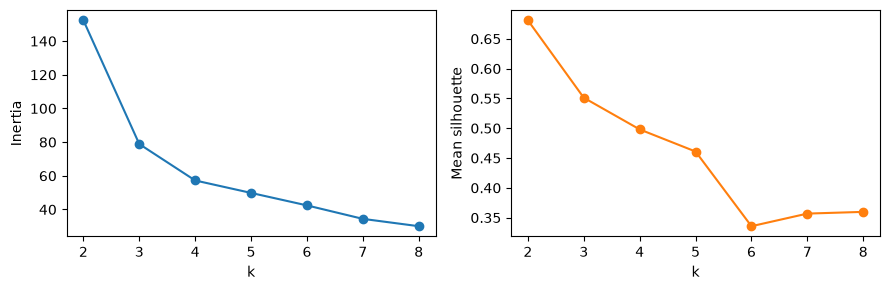

In [5]:
ks = range(2, 9)
inertias, silhouettes = [], []
for k in ks:
  model = KMeans(n_clusters=k, random_state=0).fit(X)
  inertias.append(model.inertia_)
  silhouettes.append(silhouette_score(X, model.labels_))

fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3))
left.plot(ks, inertias, "o-")
left.set_ylabel("Inertia")
right.plot(ks, silhouettes, "o-", color="C1")
right.set_ylabel("Mean silhouette")
for ax in (left, right):
  ax.set_xlabel("k")
plt.tight_layout()
plt.show()

The inertia always decreases: look for the elbow, not the minimum. Here it is at k = 3 (the inertia loses 73 from 2 to 3 clusters, then 22 from 3 to 4). The silhouette is highest at k = 2 (0.68): setosa on one side, versicolor and virginica, which overlap, on the other. It is one clue among others: the two measures disagree, and knowledge of the domain (three species) decides.